# 06. Motor 2 — estudio honesto de capacidad del Transformer

El Motor 2 responde una pregunta acotada: **¿un modelo flexible —un
Transformer tabular— aprende relaciones útiles fuera de muestra entre
el entorno de la AGEB y la actividad observada media por estación, o
solo memoriza una muestra pequeña?** El universo son las AGEBs
etiquetadas del cuaderno 04, concentradas en la zona servida y con
dependencia espacial entre vecinas.

El antiguo Motor 2 de pronóstico de stock-out quedó **descartado del
diseño vigente**: este cuaderno no contiene nada temporal.

**Lo que este motor puede decir.** Si el Transformer supera de forma
consistente a controles simples bajo validación espacial, existe
capacidad predictiva adicional en los atributos de entorno; si no, la
tesis debe declararlo.

**Lo que no puede decir.** No promete superioridad a priori, no
estima demanda latente en territorio sin servicio y sus importancias
son asociación predictiva, no causalidad.

**La tarea común.** El cuaderno 04 alimenta a los motores 1, 2 y 3
**en paralelo**: los tres resuelven la misma tarea de despliegue
—un portafolio de $B$ sitios bajo reglas de red idénticas— y
ninguno lee las salidas de los otros. El cierre de este cuaderno
aporta la respuesta del Motor 2 con su propia compuerta de dominio
y los puntajes de su modelo tabular de despliegue, **sin usar
insumos del Motor 1**.

**Insumos.** Publicaciones verificadas byte a byte: atributos del
cuaderno 03, universo/particiones/arnés y el contrato de despliegue
—sitios, celdas, reglas y métricas— del 04, y el entorno de
estaciones del 02.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.m2_analysis import (
    CONFIG, MODELS, CONTROLS, load_inputs, analyze)
from V3.src.m2_publication import stage_results

GREEN, GRAY, BLUE, RED, GOLD = "#004731", "#546E7A", "#0D47A1", "#B03A2E", "#B8860B"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data)
report = result["report"]
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "feature_analysis_id": report["upstream"]["feature_analysis_id"],
    "validation_analysis_id": report["upstream"]["validation_analysis_id"],
    "eda_analysis_id": report["upstream"]["eda_analysis_id"],
    "no_motor1_motor3_inputs":
        report["upstream"]["motor1_motor3_not_inputs"],
}]))

/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


...

/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


/Users/oscarmartinez/anaconda3/envs/CM/lib/python3.10/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


,contract_id,analysis_version,feature_analysis_id,validation_analysis_id,eda_analysis_id,no_motor1_motor3_inputs
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-motor2-3,7565adda3bc4eb91514247d2a1213f0b1c934821e762ac...,ed7bf47bafab10ca2b3144e9d38f1d06e5024ee9ba6af3...,d77ab12f05e9025f438921b34e8688e1a7562826296427...,True


## 1. Datos, objetivo y preprocesado local por pliegue

Los predictores son los atributos brutos del contrato del cuaderno 03
sobre las AGEBs evaluables del 04; el objetivo es
`log1p(actividad_media_estacion)`. A diferencia del Motor 1 —que
ajustaba su representación con todas las proyectables no excluidas—
aquí el ajuste es **supervisado y más estricto**: el preprocesador
(contrato de atributos, imputación por mediana, escalado; **sin
PCA**, los atributos entran completos a todos los modelos) se ajusta
únicamente con las filas de `train_ids`, y el objetivo solo proviene
de `train_target`. Las filas de prueba y su buffer nunca participan.

In [2]:
mets = result["cv_metrics"]
sizes = (result["ranking_detail"]
         .loc[lambda d: d.model.eq("constante")]
         [["fold_scheme", "fold", "n_train_used",
           "n_buffer_excluded", "n_relevant"]])
display(sizes.drop_duplicates())
display(Markdown(
    f"AGEBs evaluables: **{report['scope']['n_evaluable']}**; "
    f"modelos: {', '.join(MODELS)}."))

,fold_scheme,fold,n_train_used,n_buffer_excluded,n_relevant
0,fold_groupkfold_ageb,0,193,0,7
1,fold_groupkfold_ageb,1,193,0,10
2,fold_groupkfold_ageb,2,194,0,8
3,fold_groupkfold_ageb,3,194,0,4
4,fold_groupkfold_ageb,4,194,0,7
5,fold_spatial_block,0,117,70,26
6,fold_spatial_block,1,150,53,2
7,fold_spatial_block,2,139,56,3
8,fold_spatial_block,3,136,54,8
9,fold_spatial_block,4,148,45,19


AGEBs evaluables: **242**; modelos: constante, ridge, random_forest, ft_transformer.

## 2. Controles: constante, Ridge y bosque

La pregunta de capacidad solo tiene sentido contra controles
transparentes:

- **`constante`** predice la media de entrenamiento: la cota de
  plomería que todo modelo debe superar.
- **`ridge`** es un lineal regularizado cuyo alpha se elige por
  validación cruzada **interna** sobre el entrenamiento retenido —
  nunca sobre los pliegues externos.
- **`random_forest`** aporta no linealidad barata y robusta con
  hiperparámetros fijos.

Si el Transformer no supera a estos controles, su flexibilidad no se
traduce en capacidad fuera de muestra.

## 3. Arquitectura y entrenamiento controlado

El FT-Transformer tokeniza cada atributo con su propio peso y sesgo
—`token_j = x_j·W_j + b_j`—, antepone un token CLS aprendible y pasa
la secuencia por dos capas de encoder (`d_token` fijo, norm-first,
GELU); la cabeza lee solo el CLS. El objetivo se estandariza con
media y desviación del entrenamiento retenido y se invierte al
predecir.

Todos los hiperparámetros están **fijados a priori** —no hay ajuste
sobre los pliegues externos—: parada temprana con paciencia fija
sobre una partición interna **agrupada** del entrenamiento (bloques
espaciales en el esquema primario, `cvegeo` en el esquema AGEB), y
cinco semillas fijas cuyas predicciones se promedian. La variabilidad
entre semillas se reporta, no se oculta.

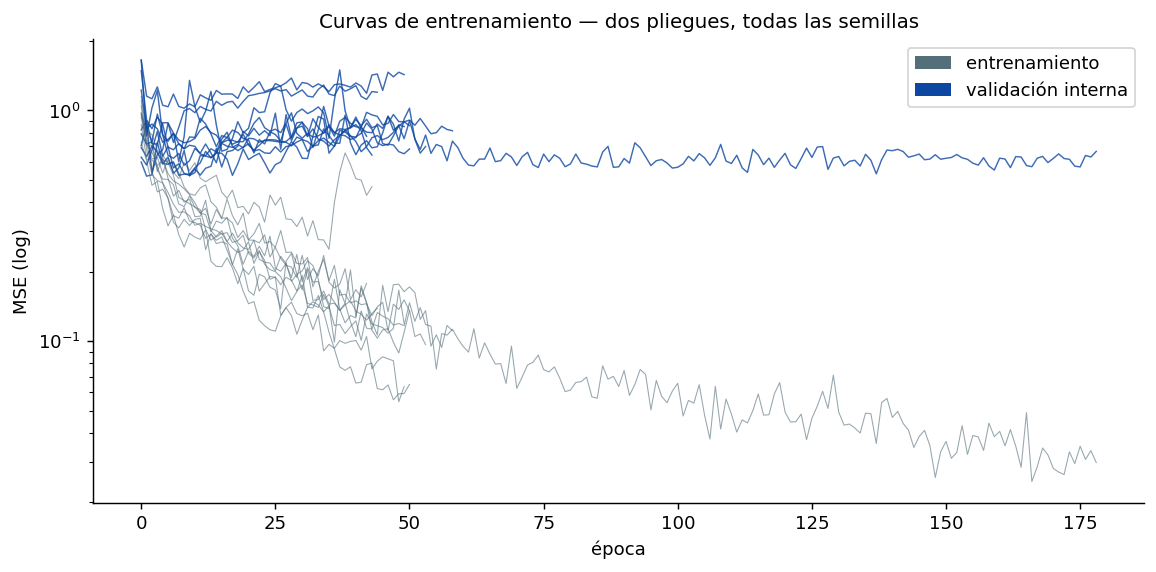

,mean,max
fold_scheme,,
fold_groupkfold_ageb,51.20,85.0
fold_spatial_block,51.84,178.0


In [3]:
tc = result["training_curves"]
prim = CONFIG["primary_scheme"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sub = tc.loc[tc.fold_scheme.eq(prim) & tc.fold.isin([0, 1])]
for (fold, seed), g in sub.groupby(["fold", "seed"]):
    ax.plot(g.epoch, g.train_loss, color=GRAY, lw=0.6, alpha=0.6)
    ax.plot(g.epoch, g.val_loss, color=BLUE, lw=0.8, alpha=0.8)
ax.set_yscale("log")
ax.set(xlabel="época", ylabel="MSE (log)",
       title="Curvas de entrenamiento — dos pliegues, todas las semillas")
ax.legend(handles=[Patch(facecolor=GRAY, label="entrenamiento"),
                   Patch(facecolor=BLUE, label="validación interna")])
plt.tight_layout(); plt.show()
epochs = (tc.groupby(["fold_scheme", "fold", "seed"]).epoch.max()
          .rename("epocas").reset_index())
display(epochs.groupby("fold_scheme").epocas.describe()[["mean", "max"]])

## 4. Evaluación fuera de muestra

Las métricas de regresión se computan **después** del backtest, desde
las predicciones almacenadas contra el objetivo del universo —nunca
dentro del motor—. Las métricas de ranking provienen del arnés del
04, el mismo que evalúa a los tres motores. La brecha
entrenamiento–prueba y el std entre semillas del Transformer son el
termómetro de memorización.

**Medias por modelo y esquema**

,model,fold_scheme,rmse,mae,r2,spearman,train_rmse,gap
0,constante,fold_groupkfold_ageb,0.498495,0.406184,-0.015751,NaN,0.498271,-0.000224
1,constante,fold_spatial_block,0.544366,0.437347,-0.302826,NaN,0.471040,-0.073325
2,ft_transformer,fold_groupkfold_ageb,0.361494,0.279571,0.444123,0.674333,0.274367,-0.087128
3,ft_transformer,fold_spatial_block,0.420556,0.331456,0.214797,0.585396,0.292422,-0.128134
4,random_forest,fold_groupkfold_ageb,0.355764,0.278786,0.472129,0.681407,0.232078,-0.123686
5,random_forest,fold_spatial_block,0.428759,0.338945,0.172027,0.540928,0.231569,-0.197191
6,ridge,fold_groupkfold_ageb,0.365999,0.287537,0.438634,0.653706,0.345260,-0.020739
7,ridge,fold_spatial_block,0.419520,0.331895,0.193849,0.531347,0.331555,-0.087965


**Ranking: medias del arnés (esquema primario)**

,precision@10,recall@10,ndcg@10
model,,,
constante,0.04,0.107692,0.383096
ft_transformer,0.36,0.190081,0.699055
random_forest,0.38,0.186134,0.698559
ridge,0.38,0.242274,0.707271


,fold,rmse,seed_rmse_std,train_rmse
35,0,0.432611,0.048126,0.260462
36,1,0.454818,0.018929,0.284297
37,2,0.429016,0.020228,0.248500
38,3,0.360757,0.019393,0.325616
39,4,0.425577,0.049765,0.343235


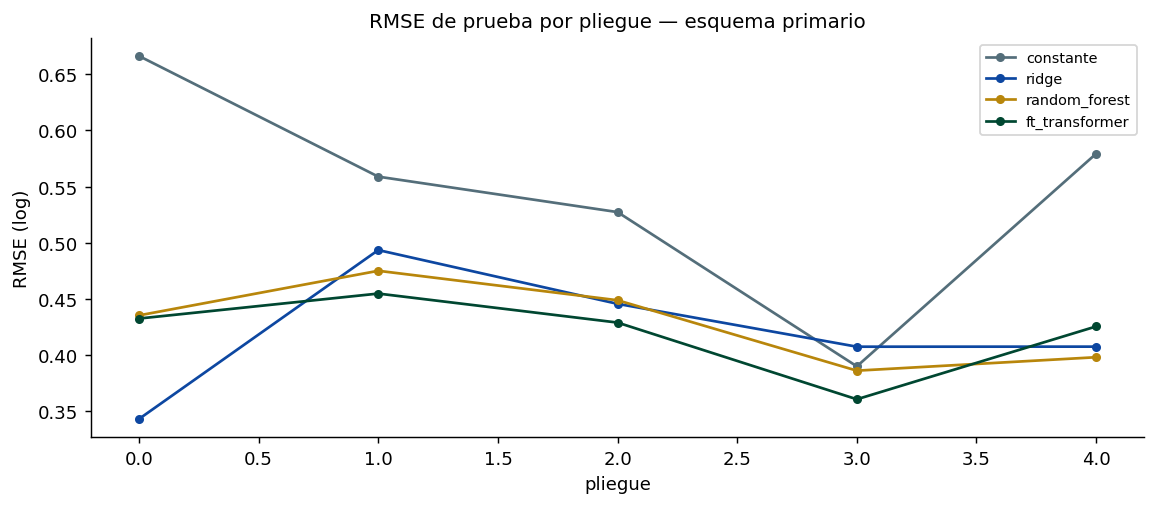

In [4]:
display(Markdown("**Medias por modelo y esquema**"))
display(result["mean_by"].assign(
    gap=lambda d: d.train_rmse - d.rmse))
display(Markdown("**Ranking: medias del arnés (esquema primario)**"))
rm = report["ranking_means_by_model_scheme"]
prim = CONFIG["primary_scheme"]
rows = [{"model": k.split("|")[0], **v}
        for k, v in rm.items() if k.endswith(prim)]
display(pd.DataFrame(rows).set_index("model")[
    [c for c in ["precision@10", "recall@10", "ndcg@10"]
     if c in pd.DataFrame(rows).columns]])
sd = result["cv_metrics"].loc[
    result["cv_metrics"].model.eq("ft_transformer")
    & result["cv_metrics"].fold_scheme.eq(prim)]
display(sd[["fold", "rmse", "seed_rmse_std", "train_rmse"]])
fig, ax = plt.subplots(figsize=(9, 4))
for model, color in zip(MODELS, [GRAY, BLUE, GOLD, GREEN]):
    sub = result["cv_metrics"].loc[
        result["cv_metrics"].model.eq(model)
        & result["cv_metrics"].fold_scheme.eq(prim)]
    ax.plot(sub.fold, sub.rmse, "-o", ms=4, label=model, color=color)
ax.set(xlabel="pliegue", ylabel="RMSE (log)",
       title="RMSE de prueba por pliegue — esquema primario")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Curva de aprendizaje — ¿más datos ayudarían?

Sobre el esquema primario se reentrenan los controles y el
Transformer (tres semillas) con fracciones crecientes del
entrenamiento retenido de cada pliegue —**la misma submuestra para
todos los modelos**—. Una pendiente descendente que aún no se aplana
sugiere que el límite es de datos, no de capacidad; una curva plana
indica que más filas del mismo tipo no ayudarían.

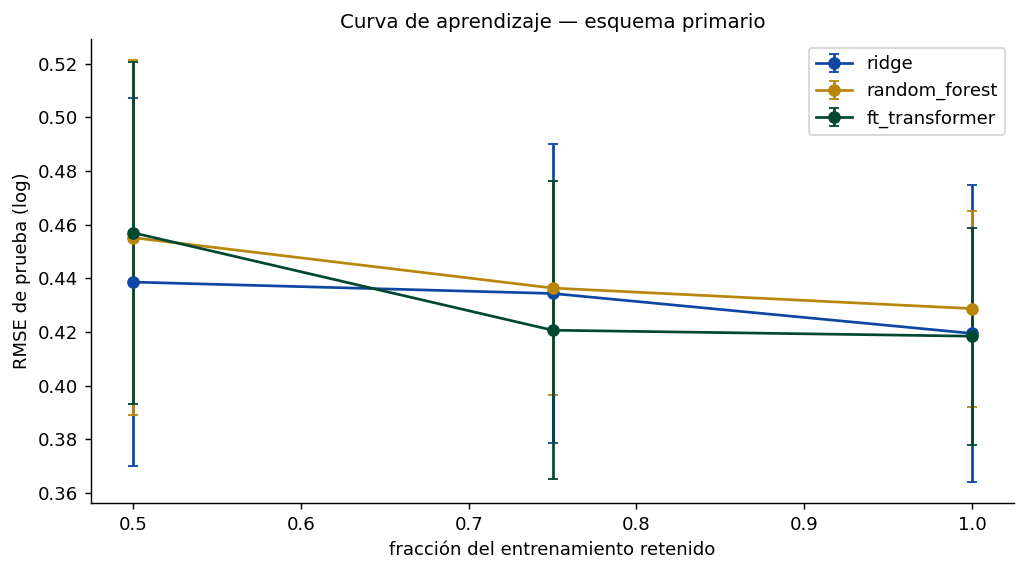

fraction,0.50,0.75,1.00
model,,,
ft_transformer,0.457029,0.420713,0.418484
random_forest,0.455191,0.436422,0.428759
ridge,0.438649,0.434397,0.419520


In [5]:
curve = result["learning_curve"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for model, color in zip(CONTROLS + ["ft_transformer"],
                        [BLUE, GOLD, GREEN]):
    sub = curve.loc[curve.model.eq(model)]
    g = sub.groupby("fraction").rmse.agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o",
                label=model, color=color, capsize=3)
ax.set(xlabel="fracción del entrenamiento retenido",
       ylabel="RMSE de prueba (log)",
       title="Curva de aprendizaje — esquema primario")
ax.legend(); plt.tight_layout(); plt.show()
display(curve.groupby(["model", "fraction"])
        .rmse.mean().unstack("fraction"))

## 6. Interpretación: importancia por permutación

En cada pliegue del esquema primario se permuta cada atributo en la
prueba y se mide el deterioro del RMSE, promediado sobre repeticiones
y pliegues. Es **asociación predictiva dentro del modelo ajustado**:
dice qué atributos usa cada modelo, no qué atributos *causan*
actividad.

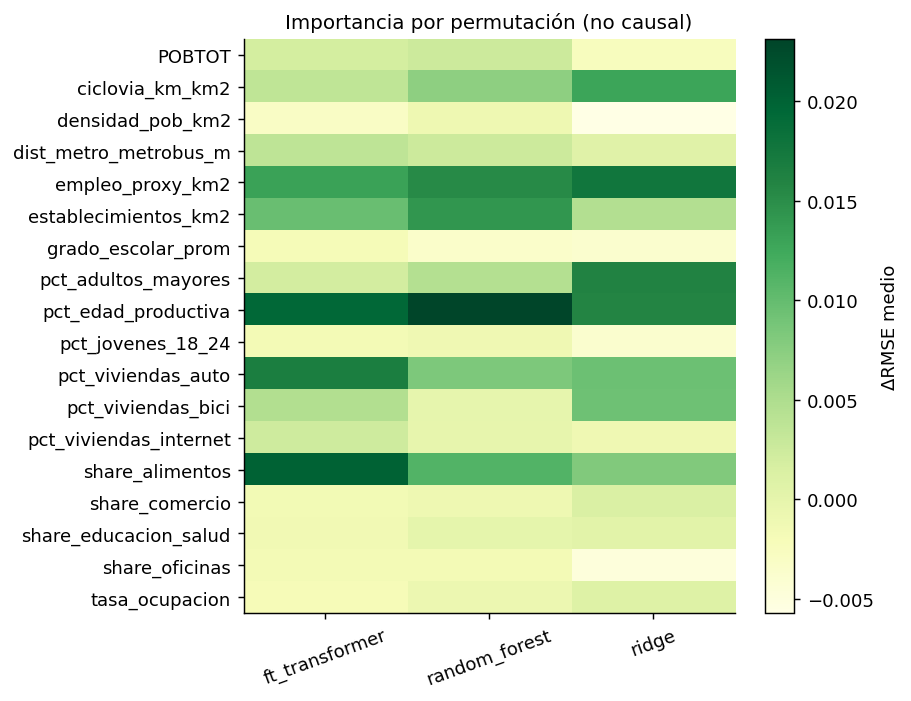

model,ft_transformer,random_forest,ridge
feature,,,
empleo_proxy_km2,0.0130,0.0153,0.0176
pct_adultos_mayores,0.0020,0.0044,0.0161
pct_edad_productiva,0.0193,0.0231,0.0159
ciclovia_km_km2,0.0036,0.0071,0.0129
pct_viviendas_auto,0.0166,0.0083,0.0094
pct_viviendas_bici,0.0047,-0.0002,0.0094
share_alimentos,0.0200,0.0112,0.0081
establecimientos_km2,0.0097,0.0141,0.0046
share_comercio,-0.0015,-0.0010,0.0014


In [6]:
imp = result["importance_summary"]
heat = imp.pivot(index="feature", columns="model",
                 values="delta_rmse_mean")
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlGn")
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=20)
ax.set_yticks(range(len(heat.index)), heat.index)
fig.colorbar(im, ax=ax, label="ΔRMSE medio")
ax.set_title("Importancia por permutación (no causal)")
plt.tight_layout(); plt.show()
display(heat.sort_values(heat.columns[-1], ascending=False).round(4))

## 7. Dictamen, despliegue exploratorio y publicación

El dictamen se computa mecánicamente con la regla declarada a priori:
el Transformer aporta solo si (a) su RMSE medio en el esquema
primario es menor que el del mejor control, (b) le gana en al menos
cuatro de cinco pliegues y (c) la mejora media supera la variabilidad
entre semillas. Si no se cumplen las tres, el cuaderno declara que
**no hay evidencia de capacidad adicional** —ese resultado también es
el resultado—.

La compuerta de dominio también es **propia**: Mahalanobis sobre el
soporte completo de su entrenamiento —todas las AGEBs servidas
etiquetadas— en el espacio estandarizado del Motor 2, y fuera de
dominio el puntaje es cero. A diferencia de la compuerta del Motor 1
—referida a la similitud con la referencia de alta actividad—, esta
mide pertenencia al soporte de los datos de entrenamiento.

In [7]:
d = report["dictamen"]
display(pd.Series({
    "transformer_aporta": d["transformer_aporta"],
    "mejor_control": d["best_control"],
    "rmse_medio_transformer": d["mean_rmse"]["ft_transformer"],
    "victorias_vs_control": f"{d['condition_b_fold_wins_vs_best_control']}/5",
    "mejora_media": d["condition_c_improvement"],
    "std_semillas_medio": d["condition_c_seed_std_mean"],
    "condicion_a": d["condition_a_rmse_below_controls"],
    "condicion_c": d["condition_c_holds"],
}, name="dictamen").to_frame())
display(pd.DataFrame([{"model": m, **v}
                      for m, v in report["beats_constante"].items()]))
dep = report["deployment"]
display(Markdown(
    f"**Despliegue.** Puntaje del portafolio: "
    f"`{dep['selected_model']}` (método propio); candidatas: "
    f"{dep['candidates']} — en dominio m2: "
    f"{dep['candidates_in_domain_m2']}, fuera: "
    f"{dep['candidates_out_domain_m2']}. Aviso: "
    f"*{dep['extrapolation_flag']}*."))
cand = result["candidate_predictions"]
display(cand.nlargest(10, "pred_selected")[
    ["cvegeo", "nom_mun", "pred_selected", "domain_status_04",
     "domain_status_m2"]])

,dictamen
transformer_aporta,False
mejor_control,ridge
rmse_medio_transformer,0.420556
victorias_vs_control,3/5
mejora_media,-0.001036
std_semillas_medio,0.031288
condicion_a,False
condicion_c,False


,model,mean_rmse_below_constante,fold_wins_vs_constante
0,ridge,True,4
1,random_forest,True,5
2,ft_transformer,True,5


**Despliegue.** Puntaje del portafolio: `random_forest` (método propio); candidatas: 2064 — en dominio m2: 892, fuera: 1172. Aviso: *extrapolación a territorio sin servicio; escala de actividad observada; exploratorio*.

,cvegeo,nom_mun,pred_selected,domain_status_04,domain_status_m2
821,0900700012475,Iztapalapa,93.661387,out_of_domain,out_of_domain
1836,0901500010235,Cuauhtémoc,86.526109,in_domain,out_of_domain
1992,0901700010795,Venustiano Carranza,83.406973,out_of_domain,out_of_domain
1839,0901500010269,Cuauhtémoc,80.424586,out_of_domain,out_of_domain
797,0900700011994,Iztapalapa,79.677391,out_of_domain,out_of_domain
1869,0901600010092,Miguel Hidalgo,79.113149,in_domain,out_of_domain
639,0900600011094,Iztacalco,77.769868,in_domain,in_domain
1823,0901500010057,Cuauhtémoc,77.161553,out_of_domain,out_of_domain
1845,0901500010324,Cuauhtémoc,76.625152,out_of_domain,out_of_domain
1865,0901500011074,Cuauhtémoc,76.187631,in_domain,in_domain


## 8. Navaja de Ockham: dictamen del Motor 2

La comparación anterior responde una segunda pregunta: **¿la
complejidad del FT-Transformer se justifica?** La regla mecánica ya
dio su veredicto: la ventaja del Transformer sobre el mejor control
es mucho menor que su propia variación entre semillas —la mejora
media no supera el desvío estándar de semillas reportado arriba—. El
FT-Transformer se retira del flujo de despliegue y se conserva
únicamente como **caso de estudio de inestabilidad estocástica**: el
mismo modelo, mismos datos, distinta semilla, respuestas distintas.

El **Random Forest** pasa a ser el modelo tabular de despliegue por
**parsimonia y estabilidad, NO por dominancia demostrada**: la
diferencia frente a Ridge es pequeña —se reporta abajo el delta de
RMSE medio y los pliegues ganados— y **ningún modelo es
predictivamente fuerte** en este protocolo: el R² espacial medio de
todos los modelos es bajo. La predicción de despliegue se mantiene
como lo que es: **exploratoria**, con bandera de extrapolación y su
compuerta de dominio propia.

In [8]:
ok = report["ockham"]
display(pd.Series({
    "transformer_fuera_del_despliegue":
        ok["transformer_removed_from_deployment"],
    "dictamen_no_added_capacity": ok["dictamen_no_added_capacity"],
    "delta_rmse_rf_menos_ridge":
        ok["rf_vs_ridge"]["delta_rmse_mean"],
    "pliegues_ganados_por_rf":
        f"{ok['rf_vs_ridge']['rf_fold_wins']}"
        f"/{ok['rf_vs_ridge']['n_folds']}",
}, name="navaja de Ockham").to_frame())
display(Markdown("**R² espacial medio por modelo** — ninguno es "
                 "predictivamente fuerte"))
display(pd.Series(ok["r2_spatial_mean"], name="r2_medio").to_frame())

,navaja de Ockham
transformer_fuera_del_despliegue,True
dictamen_no_added_capacity,True
delta_rmse_rf_menos_ridge,0.009239
pliegues_ganados_por_rf,3/5


**R² espacial medio por modelo** — ninguno es predictivamente fuerte

,r2_medio
constante,-0.302826
ridge,0.193849
random_forest,0.172027
ft_transformer,0.214797


## 9. Portafolio del Motor 2 (sin techos)

El `greedy_coverage` del contrato 04 construye los portafolios con
el puntaje del **bosque aleatorio** —expm1 de la predicción de la
AGEB anfitriona, 0 fuera del dominio m2— **sin techo por AGEB**: el
número de estaciones que recibe cada AGEB es únicamente el resultado
de la cobertura con rendimientos decrecientes.

### Remoción del techo por análogos

En la versión anterior el portafolio acotaba cada AGEB por la
mediana de densidad histórica de sus 5 análogos euclídeos por su
área. Ese techo **reproducía la densidad histórica de planeación,
no la demanda**, y su backtest —que se conserva abajo solo como
evidencia— perdía contra un comparador de densidad constante igual
a la mediana de las retenidas. El techo se retira del flujo: las
salidas de este cuaderno ya no contienen columnas ni campos de
techo (`ceiling`, `hits_ceiling`, `allocated_B*`, artefacto por
AGEB), y el portafolio cambia respecto al publicado con techos —
abajo se compara el $B=30$ anterior contra el actual, leyendo los
valores del reporte—.

,valor
mae_analog,1.438017
spearman_analog,0.311737
mae_naive,1.256198
spearman_naive,0.307494
n_rows,242
role,evidencia histórica de la remoción del techo; ...
note,"reproduce la densidad histórica de planeación,..."


,esquema_previo,new_pop_previa_B30,agebs_previo_B30,new_pop_actual_B30,agebs_actual_B30,delta_new_pop,delta_n_agebs
0,v3-motor2-2,275943.271073,26,282101.840575,25,6158.569502,-1


**Métricas de portafolio por presupuesto** (contrato común)

,stop_reason,n_selected,new_pop,new_pop_share,redundancy,n_agebs,stations_per_ageb,max_hops_network,median_hops_golden,max_hops_golden,mean_dist_to_network_m,mean_grado_escolar_prom_selected,mean_grado_escolar_prom_all_sites,mean_pct_viviendas_auto_selected,mean_pct_viviendas_auto_all_sites,out_of_domain_04_share
15,budget,15,136490.415242,0.01713,0.538192,12,"{'1': 10, '2': 1, '3+': 1}",6,8.0,10,1217.928102,11.990667,12.234022,0.481664,0.521034,0.4
30,budget,30,282101.840575,0.035404,0.525186,25,"{'1': 21, '2': 3, '3+': 1}",8,9.0,13,1359.388,11.828667,12.234022,0.452285,0.521034,0.233333
50,budget,50,428400.765425,0.053765,0.601413,41,"{'1': 33, '2': 7, '3+': 1}",17,11.0,22,1687.766814,11.7466,12.234022,0.456371,0.521034,0.2


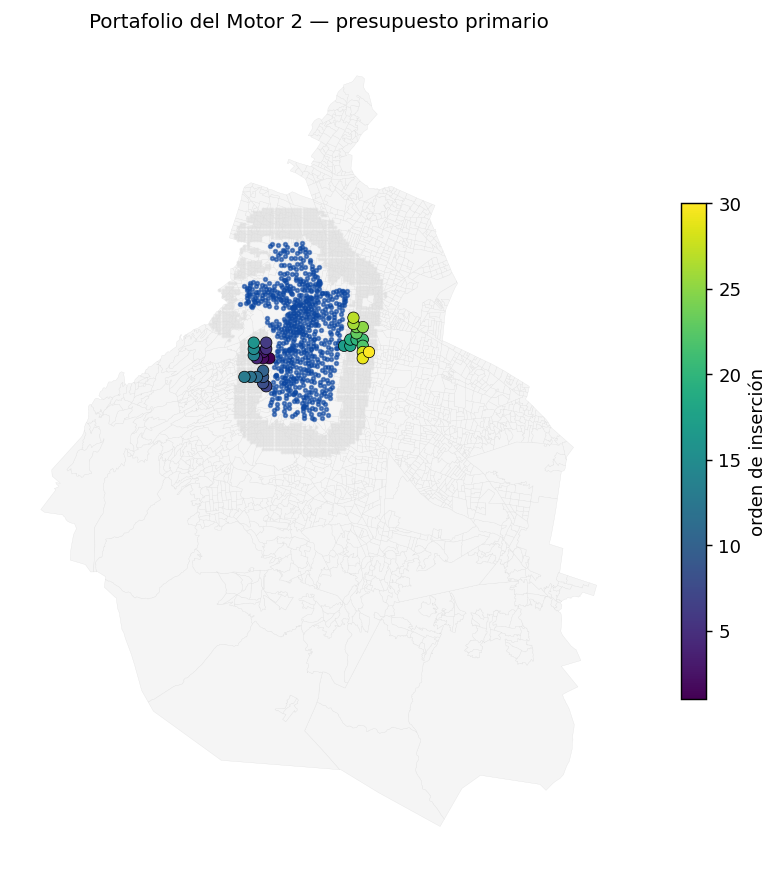

**Estaciones por AGEB** (presupuesto primario)

,n_agebs
count,
1,21
2,3
3,1


,pending_validation
0,"Analog-ceiling backtest is removal evidence, n..."
1,Capacity study says nothing about latent demand
2,"RF is the deployment model by parsimony, not b..."
3,Deployment predictions are extrapolation outsi...


**Cierre.** Estudio de capacidad y portafolio del Motor 2 publicados con verificación de integridad; sin insumos de otros motores.

<IPython.core.display.JSON object>

In [9]:
display(pd.Series(report["ceiling_backtest"], name="valor")
        .to_frame())
tr = report["portafolio"]["techo_removido"]
display(pd.DataFrame([{
    "esquema_previo": tr["previous_schema"],
    "new_pop_previa_B30": tr["previous_B30"]["new_pop"],
    "agebs_previo_B30": tr["previous_B30"]["n_agebs"],
    "new_pop_actual_B30": tr["current_B30"]["new_pop"],
    "agebs_actual_B30": tr["current_B30"]["n_agebs"],
    "delta_new_pop": tr["delta_B30_new_pop"],
    "delta_n_agebs": tr["delta_B30_n_agebs"],
}]))
display(Markdown("**Métricas de portafolio por presupuesto** "
                 "(contrato común)"))
display(pd.DataFrame(
    report["portafolio"]["por_presupuesto"]).T)
port = result["portafolios"]
prim_b = report["portafolio"]["budget_grid"][1]
sel = port.loc[port.method.eq("random_forest")
               & port.budget.eq(prim_b)]
sites = result["sites"]
stations = data["frames"]["station_env"].to_crs(
    CONFIG["metric_crs"])
universe_g = data["frames"]["universe"].to_crs(
    CONFIG["metric_crs"])
fig, ax = plt.subplots(figsize=(9, 7))
universe_g.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
                linewidth=0.15)
sites.plot(ax=ax, color="#DDDDDD", markersize=1.5, alpha=0.5)
stations.plot(ax=ax, color=BLUE, markersize=4, alpha=0.6)
sel.plot(ax=ax, column="order", cmap="viridis", markersize=40,
         edgecolor="black", linewidth=0.4, legend=True,
         legend_kwds={"label": "orden de inserción", "shrink": 0.6})
ax.set_axis_off()
ax.set_title("Portafolio del Motor 2 — presupuesto primario")
plt.tight_layout(); plt.show()
display(Markdown("**Estaciones por AGEB** (presupuesto primario)"))
display(sel.cvegeo.value_counts().value_counts().sort_index()
        .rename("n_agebs").to_frame())
display(pd.DataFrame({"pending_validation":
                      report["pending_validation"]}))
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Estudio de capacidad y portafolio "
                 "del Motor 2 publicados con verificación de "
                 "integridad; sin insumos de otros motores."))
display(JSON({"m2_report_path": report_path.relative_to(V3_DIR).as_posix()}))